# Adversarial Search: Solving Tic-Tac-Toe with Pure Monte Carlo Search

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. __Monte Carlo Search:__ Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* Pure Monte Carlo search

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [26]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [27]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

%precision 3

'%.3f'

# Pure Monte Carlo Search

See AIMA page 161ff. 

We implement a extremely simplified version.

For the current state: 
1. Simulate $N$ random playouts for each possible action and 
2. pick the action with the highest average utility.

__Important note:__ we use here a random playout policy, which ends up creating just a randomized search that works fine for this toy problem. For real applications you need to extend the code with
1. a good __playout policy__ (e.g., learned by self-play) and 
2. a __selection strategy__ (e.g., UCB1).

## Simulate playouts

In [28]:
import numpy as np

def playout(state, action, player = 'x'):
    """Perform a random playout starting with the given action on the given board 
    and return the utility of the finished game."""
    state = result(state, player, action)
    current_player = other(player)
    
    while(True):
        # reached terminal state?
        u = utility(state, player)
        if u is not None: return(u)
        
        # we use a random playout policy
        a = np.random.choice(actions(state))
        state = result(state, current_player, a)
        #print(state)
        
        # switch between players
        current_player = other(current_player)


# Playout for action 0 (top-left corner)
board = empty_board()
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))

-1
1
1
1
1


**Các bước thực hiện:**

1. Đưa người chơi **X** đi nước 'action'.

2. Chuyển lượt sang người chơi **O**.

3. Kiểm tra trò chơi đã kết thúc chưa.

4. Nếu chưa, chọn một ô trống ngẫu nhiên.

5. Thực hiện nước đi.

6. Đổi lượt người chơi.

7. Lặp lại đến khi có người thắng hoặc hòa.

8. Trả về kết quả.

**Giá trị trả về:**
+1: Người chơi đang được đánh giá thắng
0: Hòa
-1: Người chơi đang được đánh giá thua

Thực hiện 5 lần mô phỏng độc lập, tất cả đều bắt đầu bằng việc X đánh ô số 0.

In [29]:
def playouts(board, action, player = 'x', N = 100):
    """Perform N playouts following the given action for the given board."""
    return [ playout(board, action, player) for i in range(N) ]

u = playouts(board, 0)
print("Playout results:", u)

print(f"mean utility: {np.mean(u)}")

p_win = sum(np.array(u) == +1)/len(u)
p_loss = sum(np.array(u) == -1)/len(u)
p_draw = sum(np.array(u) == 0)/len(u)
print(f"win probability: {p_win}")
print(f"loss probability: {p_loss}")
print(f"draw probability: {p_draw}")

Playout results: [-1, -1, 1, 1, 0, 1, 1, -1, 1, 1, 1, -1, 1, 1, 1, 1, -1, -1, 1, -1, 1, -1, 1, 1, -1, 0, 1, 1, -1, 1, 1, 1, -1, -1, 1, 1, 1, 1, 0, 1, 1, 1, 1, -1, 0, 1, 1, -1, -1, 0, -1, -1, 0, -1, 1, 1, -1, 0, 1, 1, 1, -1, 1, 1, 1, 1, 1, -1, -1, 1, 1, 0, 0, -1, -1, 1, 1, -1, 1, 1, -1, 1, 1, -1, 1, 1, 1, 1, -1, 1, -1, -1, 1, 0, 1, 1, 1, 1, 1, -1]
mean utility: 0.28
win probability: 0.59
loss probability: 0.31
draw probability: 0.1


Khác với **playout()** chỉ mô phỏng một ván, **playouts()** mô phỏng N ván.

- mean utility: Điểm trung bình của 100 ván.

- p_win: Tỷ lệ thắng.

- p_loss: Tỷ lệ thua.

- p_draw: Tỷ lệ hòa.

Ví dụ nếu kết quả 100 ván là:

- Thắng: 40 ván. => P(win) = 40/100 = 0.4

- Hòa: 30 ván. => P(draw) = 30/100 = 0.3

- Thua: 30 ván. => P(Loss) = 30/100 = 0.3

- Điểm trung bình: U = (0.4 * 1) + (0.3 * 0) + (0.3 * (-1)) = 0.4 - 0.3 = 0.1

Điểm càng cao thì nước đi càng tốt đối với người chơi đang được đánh giá.

__Note:__ This shows that the player who goes first has a significant advantage in __pure random play.__ Real players do not play randomly, a better playout policy would be good.

## Pure Monte Carlo Search

In [30]:
import math

DEBUG = 1


def pmcs(board, N = 100, player = 'x'):
    """Pure Monte Carlo Search. Returns the action that has the largest average utility.
    The N playouts are evenly divided between the possible actions."""
    global DEBUG
    
    acts = actions(board) #lấy nước đi hợp lệ
    n = math.floor(N/len(acts)) #chia số lần mô phỏng cho các nước đi
    if DEBUG >= 1: print(f"Actions: {acts} ({N} total playouts = {n} playouts per action)")
    
    ps = { i : np.mean(playouts(board, i, player, N = n)) for i in acts } #tính điểm trung bình của từng nước đi
    if DEBUG >= 1: display(ps)
        
    action = max(ps, key=ps.get) #chọn nước đi có điểm trung bình cao nhất
    return action

board = empty_board()
display(board)
%time print(pmcs(board))

print()
print("10000 playouts give a better utility estimate.")
%time print(pmcs(board, N = 10000))

[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']

Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (100 total playouts = 11 playouts per action)


{0: 0.727,
 1: 0.091,
 2: 0.091,
 3: 0.545,
 4: 0.727,
 5: 0.000,
 6: 0.455,
 7: -0.273,
 8: 0.182}

0
CPU times: total: 31.2 ms
Wall time: 42.3 ms

10000 playouts give a better utility estimate.
Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (10000 total playouts = 1111 playouts per action)


{0: 0.400,
 1: 0.197,
 2: 0.369,
 3: 0.154,
 4: 0.547,
 5: 0.166,
 6: 0.288,
 7: 0.186,
 8: 0.371}

4
CPU times: total: 2.2 s
Wall time: 2.19 s


**Lưu ý:**

Nếu N không chia hết cho các nước đi thì số mô phỏng thực tế sẽ nhỏ hơn N do sử dụng floor().

Ví dụ: bàn trống, N = 100 thì thực tế có 9*11 = 99 playout

Looks like the center and the corners are a lot better.

## Some Tests

### x is about to win (play 8)


Board:


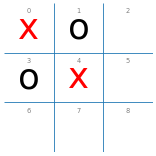


Actions: [2, 5, 6, 7, 8] (100 total playouts = 20 playouts per action)


{2: 0.750, 5: 0.600, 6: 0.950, 7: 0.550, 8: 1.000}

8

CPU times: total: 15.6 ms
Wall time: 14.7 ms


In [31]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

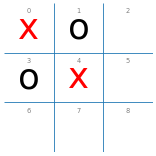


N = 10
Actions: [2, 5, 6, 7, 8] (10 total playouts = 2 playouts per action)


{2: 1.000, 5: 0.500, 6: 1.000, 7: 0.500, 8: 1.000}

2

CPU times: total: 0 ns
Wall time: 3.92 ms

N = 100
Actions: [2, 5, 6, 7, 8] (100 total playouts = 20 playouts per action)


{2: 0.800, 5: 0.700, 6: 0.800, 7: 0.850, 8: 1.000}

8

CPU times: total: 15.6 ms
Wall time: 14 ms

N = 1000
Actions: [2, 5, 6, 7, 8] (1000 total playouts = 200 playouts per action)


{2: 0.860, 5: 0.680, 6: 0.790, 7: 0.620, 8: 1.000}

8

CPU times: total: 109 ms
Wall time: 95.1 ms


In [32]:
# Thuc nghiem so lan mo phong
Ns = [10, 100, 1000]

board = empty_board()
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

show_board(board)

for N in Ns:
    print(f"\nN = {N}")
    %time display(pmcs(board, N=N))

### o is about to win

Board:


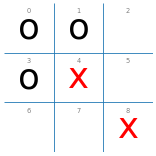


Actions: [2, 5, 6, 7] (100 total playouts = 25 playouts per action)


{2: 0.280, 5: -0.760, 6: -0.120, 7: -1.000}

2

CPU times: total: 15.6 ms
Wall time: 12.4 ms

Actions: [2, 5, 6, 7] (1000 total playouts = 250 playouts per action)


{2: -0.128, 5: -0.624, 6: 0.008, 7: -0.640}

6

CPU times: total: 78.1 ms
Wall time: 75.2 ms


In [33]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

print()
%time display(pmcs(board, N = 1000))

### x can draw if it chooses 7

Board:


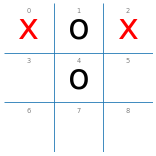


Actions: [3, 5, 6, 7, 8] (100 total playouts = 20 playouts per action)


{3: -0.300, 5: -0.150, 6: -0.250, 7: 0.100, 8: -0.250}

7

CPU times: total: 31.2 ms
Wall time: 17.6 ms


In [34]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

### Empty board: Only a draw an be guaranteed

Board:


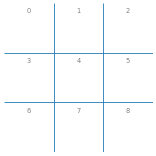


Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (5000 total playouts = 555 playouts per action)


{0: 0.366,
 1: 0.249,
 2: 0.362,
 3: 0.195,
 4: 0.555,
 5: 0.205,
 6: 0.359,
 7: 0.207,
 8: 0.400}

4

CPU times: total: 1.08 s
Wall time: 1.09 s


In [35]:
board = empty_board() 

print("Board:")
show_board(board)

print()
%time display(pmcs(board, N = 5000))

### A bad situation

Board:


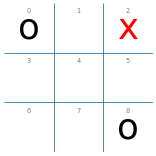


Actions: [1, 3, 4, 5, 6, 7] (100 total playouts = 16 playouts per action)


{1: -0.750, 3: -0.375, 4: -0.062, 5: -0.750, 6: -0.125, 7: -0.500}

4

CPU times: total: 15.6 ms
Wall time: 16.4 ms


In [36]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

__Note:__ It looks like random player o is very unlikely to block x and take advantage of the trap by playing the bottom left corner!

## Experiments

### Pure Monte Carlo Search vs. Random

In [37]:
def pmcs10_player(board, player = 'x'):
    action = pmcs(board, N = 10, player = player)
    return action

def pmcs100_player(board, player = 'x'):
    action = pmcs(board, N = 100, player = player)
    return action

def pmcs1000_player(board, player = 'x'):
    action = pmcs(board, N = 1000, player = player)
    return action


DEBUG = 1
print("PMCS vs. random:")
display(play(pmcs10_player, random_player, N = 1))

PMCS vs. random:
Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (10 total playouts = 1 playouts per action)


{0: -1.000,
 1: -1.000,
 2: 0.000,
 3: 1.000,
 4: 1.000,
 5: 1.000,
 6: -1.000,
 7: -1.000,
 8: 0.000}

Actions: [0, 1, 2, 4, 5, 7, 8] (10 total playouts = 1 playouts per action)


{0: 1.000, 1: -1.000, 2: -1.000, 4: 1.000, 5: 1.000, 7: -1.000, 8: -1.000}

Actions: [1, 2, 4, 5, 8] (10 total playouts = 2 playouts per action)


{1: 0.000, 2: 0.000, 4: -1.000, 5: 0.000, 8: 0.000}

Actions: [2, 5, 8] (10 total playouts = 3 playouts per action)


{2: 1.000, 5: -1.000, 8: 0.333}

{'x': 1, 'o': 0, 'd': 0}

In [38]:
DEBUG = 0
print("PMCS (10) vs. random:")
%time display(play(pmcs10_player, random_player))

print()
print("random vs. PMCS (10)")
%time display(play(random_player, pmcs10_player))

PMCS (10) vs. random:


{'x': 86, 'o': 10, 'd': 4}

CPU times: total: 438 ms
Wall time: 457 ms

random vs. PMCS (10)


{'x': 26, 'o': 68, 'd': 6}

CPU times: total: 297 ms
Wall time: 314 ms


In [39]:
DEBUG = 0
print("PMCS (100) vs. random:")
%time display(play(pmcs100_player, random_player))

print()
print("random vs. PMCS (100)")
%time display(play(random_player, pmcs100_player))

PMCS (100) vs. random:


{'x': 98, 'o': 2, 'd': 0}

CPU times: total: 5.91 s
Wall time: 6.05 s

random vs. PMCS (100)


{'x': 7, 'o': 87, 'd': 6}

CPU times: total: 5.02 s
Wall time: 5.18 s


In [40]:
DEBUG = 0
print("PMCS (100) vs. PMCS (10):")
%time display(play(pmcs100_player, pmcs10_player))

print()
print("PMCS (10) vs. PMCS (100)")
%time display(play(pmcs10_player, pmcs100_player))

PMCS (100) vs. PMCS (10):


{'x': 92, 'o': 1, 'd': 7}

CPU times: total: 6.64 s
Wall time: 6.79 s

PMCS (10) vs. PMCS (100)


{'x': 46, 'o': 42, 'd': 12}

CPU times: total: 5.41 s
Wall time: 5.53 s


**Note 1:** You can try `pmcs_1000`, but it will take a few minutes to run 100 games.

**Note 2:** The important advantage about Monte Carlo Search is that we do not need to define a heuristic evaluation function to decide what boards are good.

### **Bài 5:**

Chạy cùng 5 trạng thái kiểm thử với N = 10, 100 và 1000. Vì PMCS dùng mô phỏng ngẫu nhiên, nước đi và thời gian có thể khác nhau giữa các lần chạy.

In [41]:
import time
import pandas as pd

test_states = []

board = empty_board()
board[0] = 'x'; board[1] = 'o'; board[3] = 'o'; board[4] = 'x'
test_states.append(('X sắp thắng', board))

board = empty_board()
board[0] = 'o'; board[1] = 'o'; board[3] = 'o'; board[4] = 'x'; board[8] = 'x'
test_states.append(('O tạo đe dọa', board))

board = empty_board()
board[0] = 'x'; board[1] = 'o'; board[2] = 'x'; board[4] = 'o'
test_states.append(('X có thể tìm đường hòa', board))

test_states.append(('Bàn cờ rỗng', empty_board()))

board = empty_board()
board[0] = 'o'; board[2] = 'x'; board[8] = 'o'
test_states.append(('Tình huống bất lợi', board))

rows = []
for state_name, state in test_states:
    for N in [10, 100, 1000]:
        start = time.perf_counter()
        action = pmcs(state, N=N, player='x')
        elapsed = time.perf_counter() - start
        rows.append({'Trạng thái': state_name, 'N': N,
                     'Nước đi': action, 'Thời gian (giây)': elapsed})

df_tests = pd.DataFrame(rows)
display(df_tests)

,Trạng thái,N,Nước đi,Thời gian (giây)
0,X sắp thắng,10,5,0.003609
1,X sắp thắng,100,8,0.024242
2,X sắp thắng,1000,8,0.263436
3,O tạo đe dọa,10,2,0.001130
4,O tạo đe dọa,100,2,0.014560
5,O tạo đe dọa,1000,6,0.130327
6,X có thể tìm đường hòa,10,3,0.002199
7,X có thể tìm đường hòa,100,7,0.023755
8,X có thể tìm đường hòa,1000,7,0.201378
9,Bàn cờ rỗng,10,0,0.005808


**Nhận xét thực nghiệm**
- Khi tăng N từ 10 lên 100 hoặc 1000, số lần mô phỏng cho mỗi nước đi tăng lên nên ước lượng utility thường ổn định hơn.
- Đổi lại, thời gian tính toán tăng.
- N nhỏ có thể chọn nước đi chưa tốt do kết quả phụ thuộc nhiều vào các ván mô phỏng ngẫu nhiên.
- PMCS không cần xây dựng hàm heuristic thủ công; nó dùng kết quả các ván mô phỏng để ước lượng chất lượng nước đi.
- Kết quả đấu với Random Agent cần kiểm tra cả hai vị trí X và O vì X luôn được đi trước và có lợi thế trong trò chơi.

#### **Thực nghiệm PMCS đấu với Random Agent:**
Mỗi cấu hình chạy 100 ván khi PMCS đi trước (X) và 100 ván khi PMCS đi sau (O), để giảm ảnh hưởng của lợi thế đi trước.

In [42]:

def make_pmcs_player(N):
    def player(board, player='x'):
        return pmcs(board, N=N, player=player)
    return player


match_rows = []

for N in [10, 100]:
    agent = make_pmcs_player(N)

    for seat in ['X', 'O']:
        start = time.perf_counter()

        if seat == 'X':
            result_counts = play(agent, random_player, N=100)
            agent_wins = result_counts['x']
            agent_losses = result_counts['o']
        else:
            result_counts = play(random_player, agent, N=100)
            agent_wins = result_counts['o']
            agent_losses = result_counts['x']

        elapsed = time.perf_counter() - start

        total_games = 100
        draws = result_counts['d']

        # Tinh ty le
        win_rate = agent_wins / total_games * 100
        draw_rate = draws / total_games * 100
        loss_rate = agent_losses / total_games * 100

        match_rows.append({
            'PMCS': N,
            'Vị trí': seat,
            'Số ván': total_games,
            'Thắng': agent_wins,
            'Hòa': draws,
            'Thua': agent_losses,
            'Thời gian (giây)': round(elapsed, 6)
        })

df_matches = pd.DataFrame(match_rows)

display(df_matches)


,PMCS,Vị trí,Số ván,Thắng,Hòa,Thua,Thời gian (giây)
0,10,X,100,89,3,8,0.698632
1,10,O,100,67,11,22,0.452692
2,100,X,100,98,2,0,6.875707
3,100,O,100,88,5,7,5.656748


1. **PMCS 10**

- X: thắng 89, hòa 3, thua 8.

- O: thắng 67, hòa 11, thua 22.

Tổng cộng **200** ván: 

Win=89+67=156 => P(Win)=(156/200)*100=78%

Draw=3+11=14 => P(Draw)=(14/200)*100=7%

Loss=8+22=30 => P(Loss)=(30/200)*100=15%

2. **PMCS 100**

- X: thắng 98, hòa 2, thua 0.

- O: thắng 88, hòa 5, thua 7.

Tổng cộng **200** ván:

Win=98+88=186 => P(Win)=(186/200)*100=93%

Draw=2+5=7 => P(Draw)=(7/200)*100=3.5%

Loss=0+7=7 => P(Loss)=(7/200)*100=3.5%


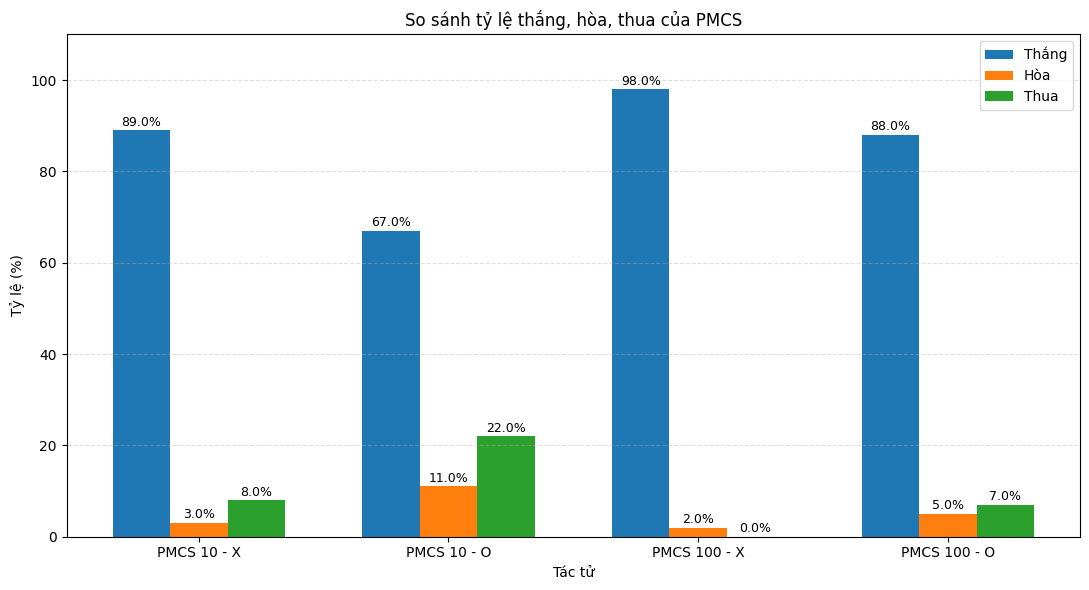

In [43]:

import matplotlib.pyplot as plt
import numpy as np

# Tinh ty le tu so van
df_plot = df_matches.copy()

df_plot['Tỷ lệ thắng (%)'] = (
    df_plot['Thắng'] / df_plot['Số ván'] * 100
)
df_plot['Tỷ lệ hòa (%)'] = (
    df_plot['Hòa'] / df_plot['Số ván'] * 100
)
df_plot['Tỷ lệ thua (%)'] = (
    df_plot['Thua'] / df_plot['Số ván'] * 100
)

# Tao nhan cho tung tac tu
labels = [
    f"PMCS {row['PMCS']} - {row['Vị trí']}"
    for _, row in df_plot.iterrows()
]

x = np.arange(len(labels))
width = 0.23

plt.figure(figsize=(11, 6))

bars1 = plt.bar(
    x - width, df_plot['Tỷ lệ thắng (%)'],
    width, label='Thắng'
)
bars2 = plt.bar(
    x, df_plot['Tỷ lệ hòa (%)'],
    width, label='Hòa'
)
bars3 = plt.bar(
    x + width, df_plot['Tỷ lệ thua (%)'],
    width, label='Thua'
)

# Hien thi gia tri tren cot
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + 1,
            f'{height:.1f}%',
            ha='center',
            fontsize=9
        )

plt.xticks(x, labels)
plt.ylabel('Tỷ lệ (%)')
plt.xlabel('Tác tử')
plt.title('So sánh tỷ lệ thắng, hòa, thua của PMCS')
plt.ylim(0, 110)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### Nhận xét và kết luận

Qua thực nghiệm, PMCS 100 cho kết quả thi đấu tốt hơn PMCS 10 khi đối đầu với Random Player. Cụ thể, **tỷ lệ thắng tổng thể** tăng từ 78% lên 93%, trong khi **tỷ lệ thua** giảm từ 15% xuống còn 3.5%.

Kết quả cũng cho thấy vị trí X có tỷ lệ thắng cao hơn vị trí O ở cả hai cấu hình. Điều này phản ánh ảnh hưởng của thứ tự lượt đi trong trò chơi Tic-Tac-Toe.

Tuy nhiên, việc tăng số lần mô phỏng làm thời gian thực thi tăng đáng kể. Vì vậy, PMCS cần cân bằng giữa số lần mô phỏng, chất lượng lựa chọn nước đi và chi phí tính toán.

Nhìn chung, thực nghiệm cho thấy tăng số lần mô phỏng có thể cải thiện hiệu quả của thuật toán Pure Monte Carlo Search khi thi đấu với Random Player. Trong phạm vi các thí nghiệm đã thực hiện, PMCS 100 đạt kết quả tốt hơn PMCS 10 nhưng cần nhiều thời gian xử lý hơn.